# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Dhea Aisya Andhini
- NIM   : 241011400093
- Kelas : Reg B *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =    93

3.0.6
2.5.4
Semua library berhasil di-import!


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1)
Shape y: (40,)


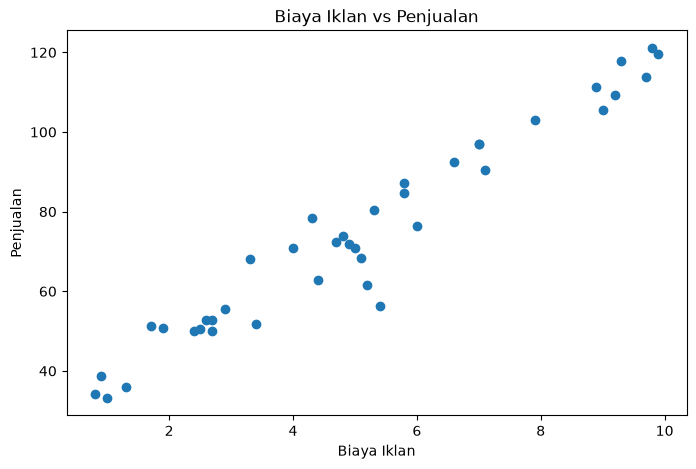

In [ ]:
# Jawaban A1

df_ads = pd.read_csv("Ads_Data.csv")

display(df_ads.head())
print("Jumlah baris data:", len(df_ads))

X = df_ads[["BiayaIklan"]].values
y = df_ads["Penjualan"].values

print("Shape X:", X.shape)
print("Shape y:", y.shape)

plt.figure(figsize=(8, 5))
plt.scatter(X, y)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan")
plt.ylabel("Penjualan")
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# Jawaban A2

def train_test_split(X, y, test_size=0.2, random_state=93):
    np.random.seed(random_state)

    indeks = np.random.permutation(len(X))
    jumlah_test = int(len(X) * test_size)

    indeks_test = indeks[:jumlah_test]
    indeks_train = indeks[jumlah_test:]

    X_train = X[indeks_train]
    X_test = X[indeks_test]
    y_train = y[indeks_train]
    y_test = y[indeks_test]

    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3

X_train_b = np.c_[np.ones((len(X_train), 1)), X_train]

theta = np.linalg.pinv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

intercept = theta[0]
koefisien = theta[1]

print("Intercept (b):", intercept)
print("Koefisien (m):", koefisien)
print(f"Persamaan regresi: y = {intercept:.4f} + {koefisien:.4f}X")

Intercept (b): 28.961242809606475
Koefisien (m): 8.935151030515591
Persamaan regresi: y = 28.9612 + 8.9352X


**Jawaban A3 (interpretasi):** Berdasarkan hasil regresi linear, nilai koefisien menunjukkan pengaruh biaya iklan terhadap penjualan. Jika koefisien bernilai positif, berarti semakin besar biaya iklan, penjualan cenderung meningkat. Sementara itu, intercept merupakan nilai perkiraan penjualan ketika biaya iklan bernilai nol.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# Jawaban A4

def mae(y_asli, y_prediksi):
    return np.mean(np.abs(y_asli - y_prediksi))

def mse(y_asli, y_prediksi):
    return np.mean((y_asli - y_prediksi) ** 2)

def rmse(y_asli, y_prediksi):
    return np.sqrt(mse(y_asli, y_prediksi))

def r2_score_manual(y_asli, y_prediksi):
    ss_res = np.sum((y_asli - y_prediksi) ** 2)
    ss_tot = np.sum((y_asli - np.mean(y_asli)) ** 2)
    return 1 - (ss_res / ss_tot)

X_train_b = np.c_[np.ones((len(X_train), 1)), X_train]
X_test_b = np.c_[np.ones((len(X_test), 1)), X_test]

y_pred_train = X_train_b @ theta
y_pred_test = X_test_b @ theta

hasil_evaluasi = pd.DataFrame({
    "Data": ["Training", "Testing"],
    "MAE": [
        mae(y_train, y_pred_train),
        mae(y_test, y_pred_test)
    ],
    "MSE": [
        mse(y_train, y_pred_train),
        mse(y_test, y_pred_test)
    ],
    "RMSE": [
        rmse(y_train, y_pred_train),
        rmse(y_test, y_pred_test)
    ],
    "R2": [
        r2_score_manual(y_train, y_pred_train),
        r2_score_manual(y_test, y_pred_test)
    ]
})

display(hasil_evaluasi.round(4))

,Data,MAE,MSE,RMSE,R2
0,Training,4.2628,33.8516,5.8182,0.9382
1,Testing,5.8367,45.9860,6.7813,0.9399


**Jawaban A4 (analisis):** Berdasarkan hasil evaluasi, nilai RMSE pada data training sebesar 5,8182 dan testing sebesar 6,7813. Artinya, hasil prediksi penjualan masih memiliki selisih dengan data sebenarnya. Nilai R² pada training sebesar 0,9382 dan testing sebesar 0,9399, yang menunjukkan bahwa model dapat menjelaskan sekitar 94% perubahan penjualan berdasarkan biaya iklan. Menurut saya, model ini sudah cukup baik karena nilai R² tinggi dan hasil evaluasi pada data training dan testing tidak jauh berbeda.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

In [ ]:
# Jawaban A5

def linear_regression_gd(X, y, learning_rate, n_iterations=5000):
    X_b = np.c_[np.ones((len(X), 1)), X]
    theta_gd = np.zeros(X_b.shape[1])
    loss_history = []

    for i in range(n_iterations):
        y_pred = X_b @ theta_gd
        error = y_pred - y

        gradient = (2 / len(y)) * (X_b.T @ error)
        theta_gd = theta_gd - learning_rate * gradient

        loss = np.mean((X_b @ theta_gd - y) ** 2)
        loss_history.append(loss)

    return theta_gd, loss_history

learning_rates = [0.001, 0.02, 0.1]
hasil_gd = {}

for lr in learning_rates:
    with np.errstate(over="ignore", invalid="ignore"):
        theta_gd, loss_history = linear_regression_gd(
            X_train, y_train, learning_rate=lr, n_iterations=5000
        )

    hasil_gd[lr] = (theta_gd, loss_history)

    print(f"\nLearning rate: {lr}")
    print("Intercept:", theta_gd[0])
    print("Koefisien:", theta_gd[1])


Learning rate: 0.001
Intercept: 25.981420891644834
Koefisien: 9.42973431411474

Learning rate: 0.02
Intercept: 28.961242809605906
Koefisien: 8.935151030515678

Learning rate: 0.1
Intercept: nan
Koefisien: nan


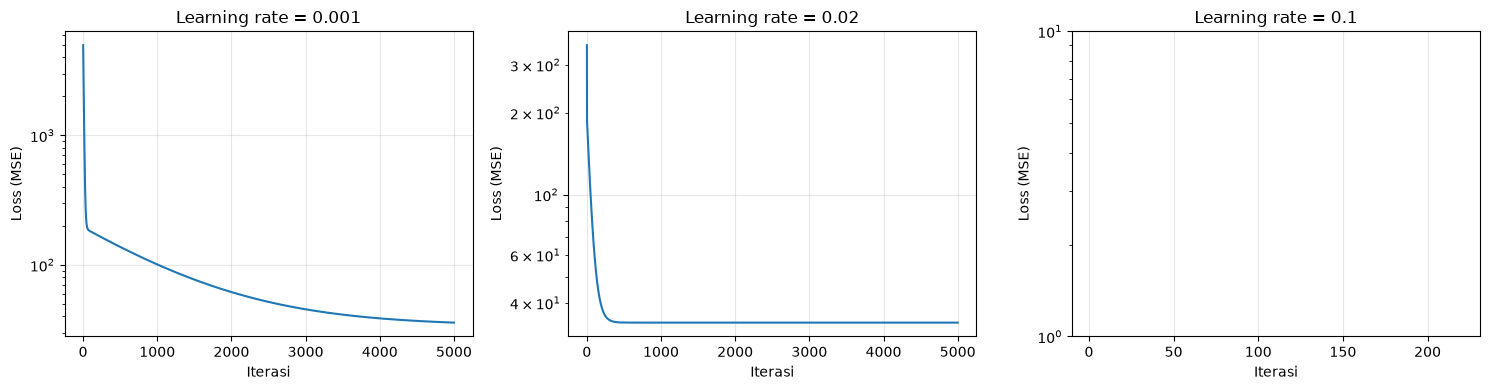

In [11]:

# perubahan loss setiap iterasi.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, lr in zip(axes, learning_rates):
    loss_history = np.array(hasil_gd[lr][1])
    iterasi = np.arange(1, len(loss_history) + 1)

    valid = np.isfinite(loss_history) & (loss_history > 0)

    ax.plot(iterasi[valid], loss_history[valid])
    ax.set_yscale("log")
    ax.set_title(f"Learning rate = {lr}")
    ax.set_xlabel("Iterasi")
    ax.set_ylabel("Loss (MSE)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):** Dari hasil percobaan, learning rate 0.001 membuat proses belajar lebih lambat karena loss turun secara bertahap. Learning rate 0.02 lebih cocok karena loss turun dengan cepat lalu stabil. Sedangkan learning rate 0.1 gagal konvergen karena nilai learning rate terlalu besar sehingga perhitungan menjadi tidak stabil dan menyebabkan overflow. Jadi, menurut saya learning rate 0.02 paling sesuai untuk data yang digunakan.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

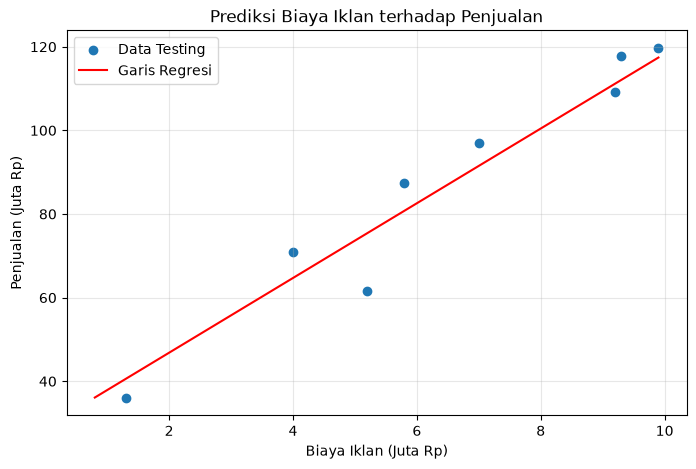

Biaya iklan 4.5 juta -> Prediksi penjualan 69.17 juta
Biaya iklan 7.0 juta -> Prediksi penjualan 91.51 juta
Biaya iklan 12.0 juta -> Prediksi penjualan 136.18 juta


In [12]:

# Jawaban A6

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, label="Data Testing")

x_garis = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_garis = theta[0] + theta[1] * x_garis

plt.plot(x_garis, y_garis, color="red", label="Garis Regresi")
plt.title("Prediksi Biaya Iklan terhadap Penjualan")
plt.xlabel("Biaya Iklan (Juta Rp)")
plt.ylabel("Penjualan (Juta Rp)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

biaya_baru = np.array([4.5, 7, 12])
prediksi = theta[0] + theta[1] * biaya_baru

for biaya, hasil in zip(biaya_baru, prediksi):
    print(f"Biaya iklan {biaya} juta -> Prediksi penjualan {hasil:.2f} juta")

**Jawaban A6 (analisis):** Berdasarkan hasil prediksi, semakin besar biaya iklan maka penjualan cenderung meningkat. Untuk biaya iklan 4,5 juta, penjualan diprediksi sebesar 69,17 juta, sedangkan biaya iklan 7 juta diprediksi sebesar 91,51 juta. Untuk biaya iklan 12 juta, hasil prediksinya sebesar 136,18 juta. Namun, prediksi 12 juta kurang bisa dipercaya karena berada di luar rentang data yang digunakan untuk melatih model. Jadi, hasil prediksi tersebut hanya perkiraan dan belum tentu sesuai dengan penjualan sebenarnya.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email Spam dan Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64
Shape X: (60, 2)
Shape y: (60,)


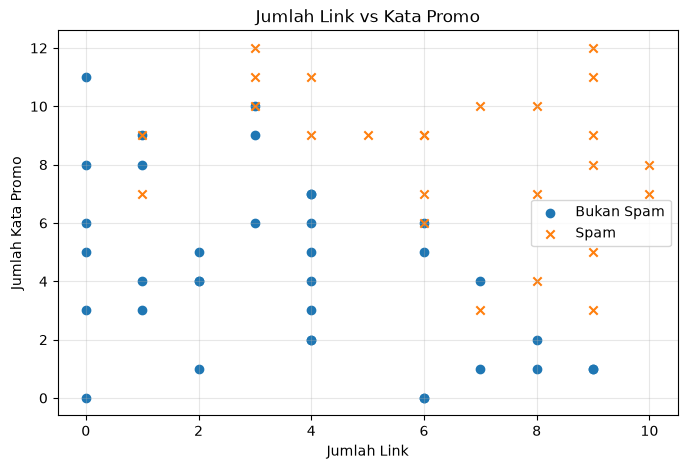

In [13]:
# Jawaban B1

df_email = pd.read_csv("Email_Data.csv")

display(df_email.head())

print("Jumlah email Spam dan Bukan Spam:")
print(df_email["Spam"].value_counts())

X = df_email[["JumlahLink", "KataPromo"]].values
y = df_email["Spam"].values

print("Shape X:", X.shape)
print("Shape y:", y.shape)

plt.figure(figsize=(8, 5))

plt.scatter(
    df_email[df_email["Spam"] == 0]["JumlahLink"],
    df_email[df_email["Spam"] == 0]["KataPromo"],
    label="Bukan Spam",
    marker="o"
)

plt.scatter(
    df_email[df_email["Spam"] == 1]["JumlahLink"],
    df_email[df_email["Spam"] == 1]["KataPromo"],
    label="Spam",
    marker="x"
)

plt.title("Jumlah Link vs Kata Promo")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -8.851671435152397
Koefisien m1 (JumlahLink): 0.7563060308534512
Koefisien m2 (KataPromo): 0.7257948988405677
P(Spam) = sigmoid(-8.8517 + (0.7563 * JumlahLink) + (0.7258 * KataPromo))
Shape X_train: (45, 2)
Shape X_test: (15, 2)


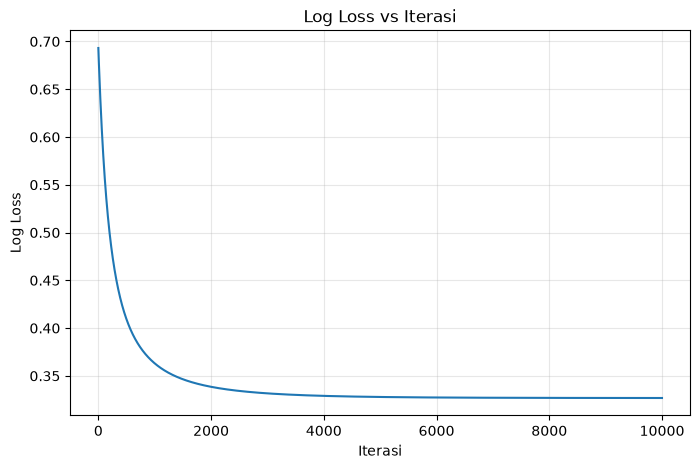

In [14]:
# Jawaban B2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def logistic_regression_gd(X, y, learning_rate=0.1, n_iterations=10000):
    X_b = np.c_[np.ones((len(X), 1)), X]
    theta = np.zeros(X_b.shape[1])
    loss_history = []

    for i in range(n_iterations):
        z = X_b @ theta
        y_pred = sigmoid(z)

        epsilon = 1e-15
        loss = -np.mean(
            y * np.log(y_pred + epsilon)
            + (1 - y) * np.log(1 - y_pred + epsilon)
        )
        loss_history.append(loss)

        gradient = (X_b.T @ (y_pred - y)) / len(y)
        theta -= learning_rate * gradient

    return theta, loss_history

theta_log, loss_history = logistic_regression_gd(
    X_train, y_train,
    learning_rate=0.1,
    n_iterations=10000
)

b = theta_log[0]
m1 = theta_log[1]
m2 = theta_log[2]

print("Intercept (b):", b)
print("Koefisien m1 (JumlahLink):", m1)
print("Koefisien m2 (KataPromo):", m2)

print(
    f"P(Spam) = sigmoid({b:.4f} "
    f"+ ({m1:.4f} * JumlahLink) "
    f"+ ({m2:.4f} * KataPromo))"
)

print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.title("Log Loss vs Iterasi")
plt.grid(True, alpha=0.3)
plt.show()

**Jawaban B2 (analisis):** Berdasarkan grafik, nilai log loss awalnya sekitar 0,69, lalu terus menurun sampai sekitar 0,33 dan akhirnya stabil. Hal ini menunjukkan bahwa model belajar dengan baik selama proses training. Nilai intercept sebesar -8,8517, sedangkan koefisien JumlahLink sebesar 0,7563 dan KataPromo sebesar 0,7258. Kedua koefisien bernilai positif, artinya semakin banyak link dan kata promosi dalam email, kemungkinan email tersebut terdeteksi sebagai spam juga semakin besar.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [15]:
# Jawaban B3

X_test_b = np.c_[np.ones((len(X_test), 1)), X_test]
y_prob = sigmoid(X_test_b @ theta_log)
y_pred = (y_prob >= 0.5).astype(int)

TP = np.sum((y_test == 1) & (y_pred == 1))
TN = np.sum((y_test == 0) & (y_pred == 0))
FP = np.sum((y_test == 0) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == 0))

accuracy = (TP + TN) / len(y_test)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

print("Confusion Matrix:")
print(np.array([[TN, FP], [FN, TP]]))
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1_score, 4))
print("TP:", TP, "| TN:", TN, "| FP:", FP, "| FN:", FN)

Confusion Matrix:
[[6 0]
 [0 9]]
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0
TP: 9 | TN: 6 | FP: 0 | FN: 0


**Jawaban B3 (analisis):** Berdasarkan hasil pengujian, model mendapatkan nilai accuracy, precision, recall, dan F1-score sebesar 100%. Artinya, semua data email testing berhasil diprediksi dengan benar. Tidak ada email yang salah dikategorikan sebagai spam maupun bukan spam.
FP adalah email biasa yang dianggap sebagai spam, sedangkan FN adalah email spam yang dianggap sebagai email biasa. Menurut saya, keduanya bisa merugikan pengguna. FP bisa membuat email penting masuk ke folder spam, sedangkan FN membuat email spam masuk ke kotak masuk. Jadi, keduanya perlu diperhatikan agar filter email bisa bekerja dengan baik.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

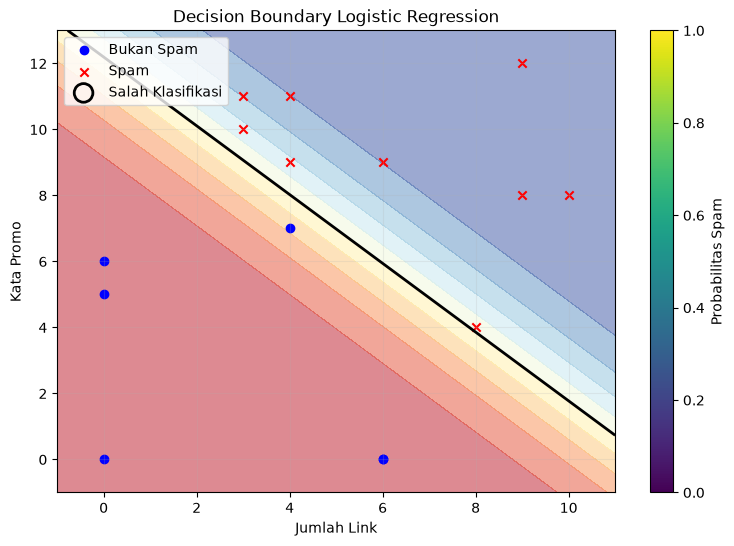

Jumlah data testing yang salah: 0


In [16]:
# Jawaban B4

x1_min, x1_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
x2_min, x2_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)

grid = np.c_[xx1.ravel(), xx2.ravel()]
grid_b = np.c_[np.ones(len(grid)), grid]
probabilitas = sigmoid(grid_b @ theta_log).reshape(xx1.shape)

X_test_b = np.c_[np.ones(len(X_test)), X_test]
y_prob = sigmoid(X_test_b @ theta_log)
y_pred = (y_prob >= 0.5).astype(int)

salah = y_pred != y_test

plt.figure(figsize=(9, 6))
plt.contourf(
    xx1, xx2, probabilitas,
    levels=np.linspace(0, 1, 11),
    cmap="RdYlBu",
    alpha=0.5
)

plt.contour(
    xx1, xx2, probabilitas,
    levels=[0.5],
    colors="black",
    linewidths=2
)

plt.scatter(
    X_test[y_test == 0, 0], X_test[y_test == 0, 1],
    c="blue", marker="o", label="Bukan Spam"
)
plt.scatter(
    X_test[y_test == 1, 0], X_test[y_test == 1, 1],
    c="red", marker="x", label="Spam"
)

plt.scatter(
    X_test[salah, 0], X_test[salah, 1],
    s=180, facecolors="none", edgecolors="black",
    linewidths=2, label="Salah Klasifikasi"
)

plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.title("Decision Boundary Logistic Regression")
plt.colorbar(label="Probabilitas Spam")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Jumlah data testing yang salah:", np.sum(salah))

for i in np.where(salah)[0]:
    print(
        f"Data ke-{i}: JumlahLink={X_test[i, 0]}, "
        f"KataPromo={X_test[i, 1]}, "
        f"Aktual={y_test[i]}, Prediksi={y_pred[i]}"
    )

**Jawaban B4 (analisis):** Decision boundary merupakan garis yang memisahkan email spam dan bukan spam berdasarkan probabilitas 0,5. Pada grafik, warna latar menunjukkan probabilitas email termasuk spam, sedangkan titik menunjukkan data testing. Berdasarkan hasil pengujian, tidak ada data testing yang salah diklasifikasikan. Artinya, model berhasil membedakan email spam dan bukan spam pada data testing yang digunakan. Namun, model tetap perlu diuji dengan data yang lebih banyak agar hasilnya lebih meyakinkan.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [17]:
# Jawaban B5

X_test_b = np.c_[np.ones((len(X_test), 1)), X_test]
y_prob = sigmoid(X_test_b @ theta_log)

thresholds = [0.3, 0.5, 0.7]
hasil_threshold = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    TP = np.sum((y_test == 1) & (y_pred_threshold == 1))
    TN = np.sum((y_test == 0) & (y_pred_threshold == 0))
    FP = np.sum((y_test == 0) & (y_pred_threshold == 1))
    FN = np.sum((y_test == 1) & (y_pred_threshold == 0))

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    hasil_threshold.append({
        "Threshold": threshold,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP,
        "Precision": precision,
        "Recall": recall
    })

df_threshold = pd.DataFrame(hasil_threshold)

display(df_threshold.round(4))

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,5,1,0,9,0.9,1.0000
1,0.5,6,0,0,9,1.0,1.0000
2,0.7,6,0,3,6,1.0,0.6667


**Jawaban B5 (analisis):** Berdasarkan hasil percobaan, threshold 0,3 menghasilkan precision 0,9 dan recall 1,0. Artinya, semua email spam berhasil ditemukan, tetapi ada satu email biasa yang salah dianggap sebagai spam. Pada threshold 0,5, precision dan recall sama-sama 1,0 sehingga semua email testing diklasifikasikan dengan benar. Sementara itu, threshold 0,7 menghasilkan precision 1,0, tetapi recall turun menjadi 0,6667 karena ada tiga email spam yang tidak terdeteksi. Menurut saya, threshold 0,5 paling cocok untuk data ini karena semua email berhasil diklasifikasikan dengan benar tanpa kesalahan FP maupun FN.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [18]:
# Jawaban B6

email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})

X_baru = email_baru[["JumlahLink", "KataPromo"]].values
X_baru_b = np.c_[np.ones(len(X_baru)), X_baru]

prob_spam = sigmoid(X_baru_b @ theta_log)

threshold = 0.5
prediksi = (prob_spam >= threshold).astype(int)

hasil_b6 = email_baru.copy()
hasil_b6["Probabilitas Spam"] = prob_spam
hasil_b6["Prediksi"] = np.where(prediksi == 1, "Spam", "Bukan Spam")

display(hasil_b6.round(4))

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi
0,E1,1,2,0.0013,Bukan Spam
1,E2,5,6,0.3284,Bukan Spam
2,E3,9,10,0.9946,Spam
3,E4,2,11,0.6558,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk menentukan data masuk ke kategori tertentu, contohnya email spam atau bukan spam. Fungsi sigmoid digunakan untuk mengubah hasil perhitungan menjadi nilai probabilitas antara 0 sampai 1, sehingga bisa ditentukan data tersebut masuk ke kelas yang mana.

**Jawaban C2:** Normal Equation digunakan untuk menghitung koefisien secara langsung, sedangkan Gradient Descent menghitung koefisien secara bertahap melalui beberapa iterasi. Menurut saya, Gradient Descent lebih cocok digunakan untuk data yang besar karena proses perhitungannya bisa dilakukan secara bertahap.

**Jawaban C3:** Data testing digunakan untuk melihat apakah model bisa memprediksi data yang belum pernah dipelajari sebelumnya. Kalau model hanya bagus pada data training, belum tentu hasilnya bagus pada data baru. Kondisi ketika model terlalu fokus mempelajari data training dan kurang baik saat memprediksi data baru disebut overfitting.

**Jawaban C4:** Linear Regression menggunakan MSE karena hasil prediksinya berupa angka, sehingga kesalahannya bisa dihitung dari selisih nilai asli dan nilai prediksi. Sementara itu, Logistic Regression menggunakan log loss karena model ini menghasilkan probabilitas untuk menentukan suatu data masuk ke kelas tertentu.

**Jawaban C5:** Hasil model bisa berbeda walaupun menggunakan dataset dan algoritma yang sama karena pengaturan yang digunakan belum tentu sama. Misalnya, pembagian data, random state, learning rate, dan jumlah iterasi bisa memengaruhi hasil perhitungan. Jadi, perbedaan pengaturan tersebut bisa membuat hasil koefisien atau akurasi menjadi berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:

# Jawaban Bonus

RANDOM_STATE = 93

# Fungsi pembagian data
def train_test_split(X, y, test_size=0.2, random_state=93):
    np.random.seed(random_state)

    indeks = np.random.permutation(len(X))
    jumlah_test = int(len(X) * test_size)

    indeks_test = indeks[:jumlah_test]
    indeks_train = indeks[jumlah_test:]

    X_train = X[indeks_train]
    X_test = X[indeks_test]
    y_train = y[indeks_train]
    y_test = y[indeks_test]

    return X_train, X_test, y_train, y_test

# Import library
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score, confusion_matrix

# 1. Linear Regression
df_ads = pd.read_csv("Ads_Data.csv")

X_ads = df_ads[["BiayaIklan"]].values
y_ads = df_ads["Penjualan"].values

X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

model_linear = LinearRegression()
model_linear.fit(X_train_ads, y_train_ads)

y_pred_linear = model_linear.predict(X_test_ads)

print("Linear Regression ")
print("Intercept:", model_linear.intercept_)
print("Koefisien:", model_linear.coef_[0])
print("MSE Testing:", mean_squared_error(y_test_ads, y_pred_linear))


# 2. Logistic Regression
df_email = pd.read_csv("Email_Data.csv")

X_email = df_email[["JumlahLink", "KataPromo"]].values
y_email = df_email["Spam"].values

X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

model_logistic = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=10000
)

model_logistic.fit(X_train_email, y_train_email)

y_pred_logistic = model_logistic.predict(X_test_email)

print("\nLogistic Regression ")
print("Intercept:", model_logistic.intercept_[0])
print("Koefisien:", model_logistic.coef_[0])
print("Accuracy:", accuracy_score(y_test_email, y_pred_logistic))
print("Confusion Matrix:")
print(confusion_matrix(y_test_email, y_pred_logistic))

# 3. Analisis Perbandingan
print("\nAnalisis ")
print("Linear Regression menggunakan MSE untuk mengukur kesalahan prediksi.")
print("Logistic Regression menggunakan accuracy dan confusion matrix untuk evaluasi klasifikasi.")
print("Koefisien Logistic Regression bisa berbeda dari hasil manual")
print("karena scikit-learn menggunakan regularisasi L2 secara default.")

Linear Regression 
Intercept: 28.961242809606112
Koefisien: 8.935151030515645
MSE Testing: 45.98599884562975

Logistic Regression 
Intercept: -8.241612536127183
Koefisien: [0.6985491  0.67423785]
Accuracy: 1.0
Confusion Matrix:
[[6 0]
 [0 9]]

Analisis 
Linear Regression menggunakan MSE untuk mengukur kesalahan prediksi.
Logistic Regression menggunakan accuracy dan confusion matrix untuk evaluasi klasifikasi.
Koefisien Logistic Regression bisa berbeda dari hasil manual
karena scikit-learn menggunakan regularisasi L2 secara default.


**Jawaban Bonus (analisis):**

Berdasarkan hasil percobaan, nilai koefisien Linear Regression dari scikit-learn hampir sama dengan hasil perhitungan manual. Nilai MSE testing sebesar 45,986 menunjukkan bahwa masih ada kesalahan dalam hasil prediksi penjualan.
Pada Logistic Regression, nilai accuracy yang didapatkan sebesar 100%, artinya semua data testing berhasil diklasifikasikan dengan benar. Hasil koefisiennya sedikit berbeda dari perhitungan manual karena scikit-learn menggunakan regularisasi L2, sedangkan metode manual yang digunakan tidak memakai regularisasi tersebut.